<a href="https://colab.research.google.com/github/junaed1031/Smart-Crop-Recommendation-System/blob/main/lab_final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
# importent library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [29]:
# data load
df = pd.read_csv('Crop_recommendation.csv')

In [30]:
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows of the dataset:")
display(df.head())

Dataset Shape: (2200, 8)

First 5 rows of the dataset:


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [31]:
print("\nMissing Values in each column:")
print(df.isnull().sum())


Missing Values in each column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


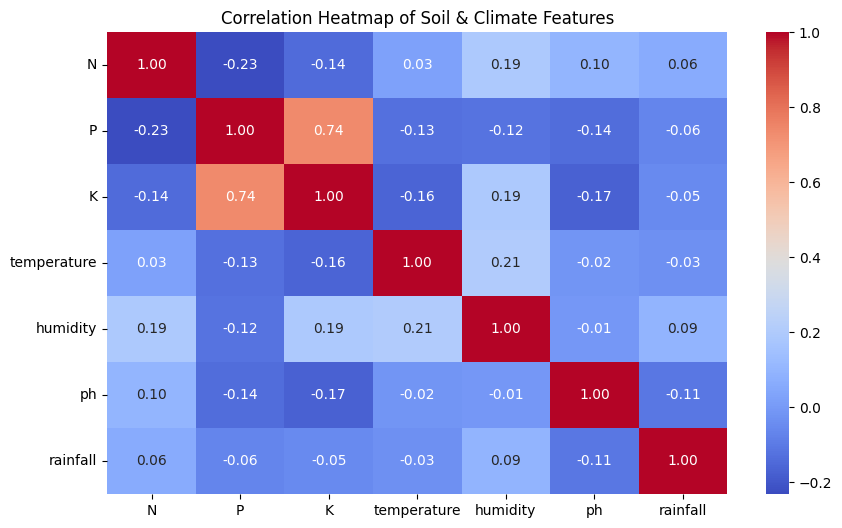

In [32]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.drop('label', axis=1).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Soil & Climate Features")
plt.show()

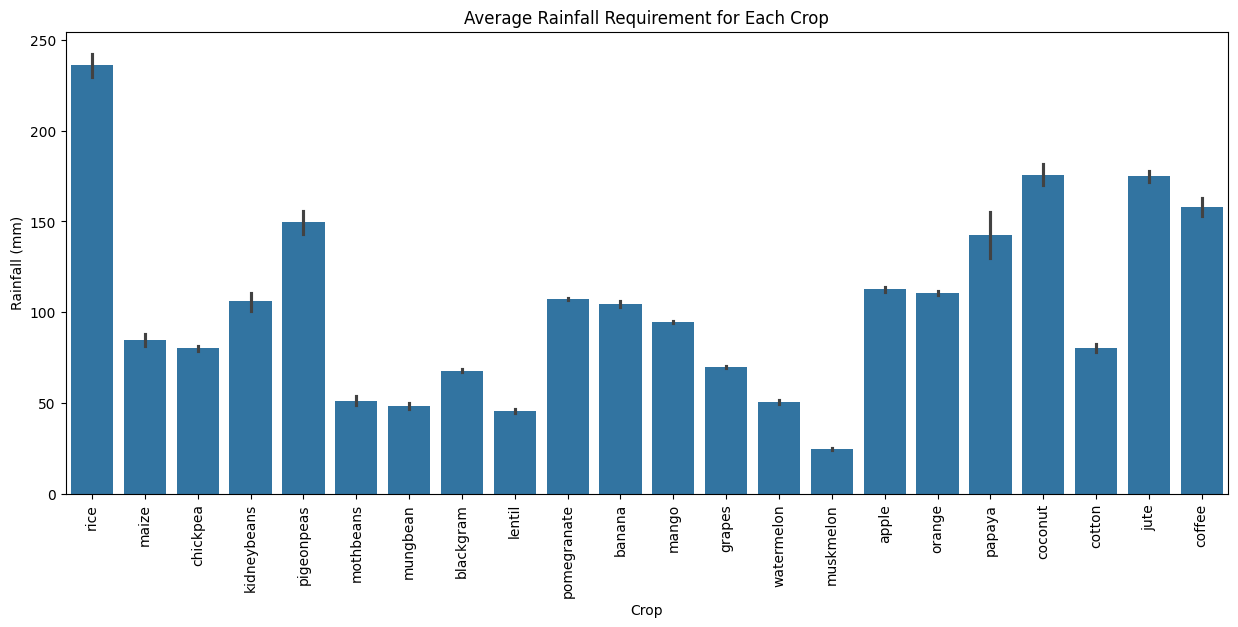

In [33]:
plt.figure(figsize=(15, 6))
sns.barplot(x='label', y='rainfall', data=df)
plt.xticks(rotation=90)
plt.title("Average Rainfall Requirement for Each Crop")
plt.ylabel("Rainfall (mm)")
plt.xlabel("Crop")
plt.show()

In [34]:
# Importing necessary libraries for modeling and evaluation
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [35]:
#Separating Features (X) and Target (y)
X = df.drop('label', axis=1)
y = df['label']

In [36]:
#Splitting the dataset into Training and Testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [37]:
# Scaling ensures all features (like temperature and rainfall) contribute equally to the model
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [38]:
#Hyperparameter Tuning using GridSearchCV to find the best model parameters
print("Starting Hyperparameter Tuning for Random Forest...\n")

# Defining the parameter grid to test
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

# Initializing the base model
rf_model = RandomForestClassifier(random_state=42)

# Setting up GridSearchCV (Testing 12 combinations using 5-fold Cross Validation)
grid_search = GridSearchCV(estimator=rf_model, param_grid=param_grid, cv=5, n_jobs=-1, verbose=1)
grid_search.fit(X_train_scaled, y_train)

# Extracting the best model from GridSearch
best_rf_model = grid_search.best_estimator_
print(f"\nBest Parameters found: {grid_search.best_params_}")

Starting Hyperparameter Tuning for Random Forest...

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best Parameters found: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 50}


In [39]:
# Model Evaluation on Test Data
y_pred = best_rf_model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy on Test Data: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy on Test Data: 98.41%

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        23
      banana       1.00      1.00      1.00        21
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        26
     coconut       1.00      1.00      1.00        27
      coffee       1.00      1.00      1.00        17
      cotton       1.00      1.00      1.00        17
      grapes       1.00      1.00      1.00        14
        jute       0.85      0.96      0.90        23
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.85      1.00      0.92        11
       maize       1.00      1.00      1.00        21
       mango       1.00      1.00      1.00        19
   mothbeans       1.00      0.92      0.96        24
    mungbean       1.00      1.00      1.00        19
   muskmelon       1.00      1.00      1.00        17
      orange       1

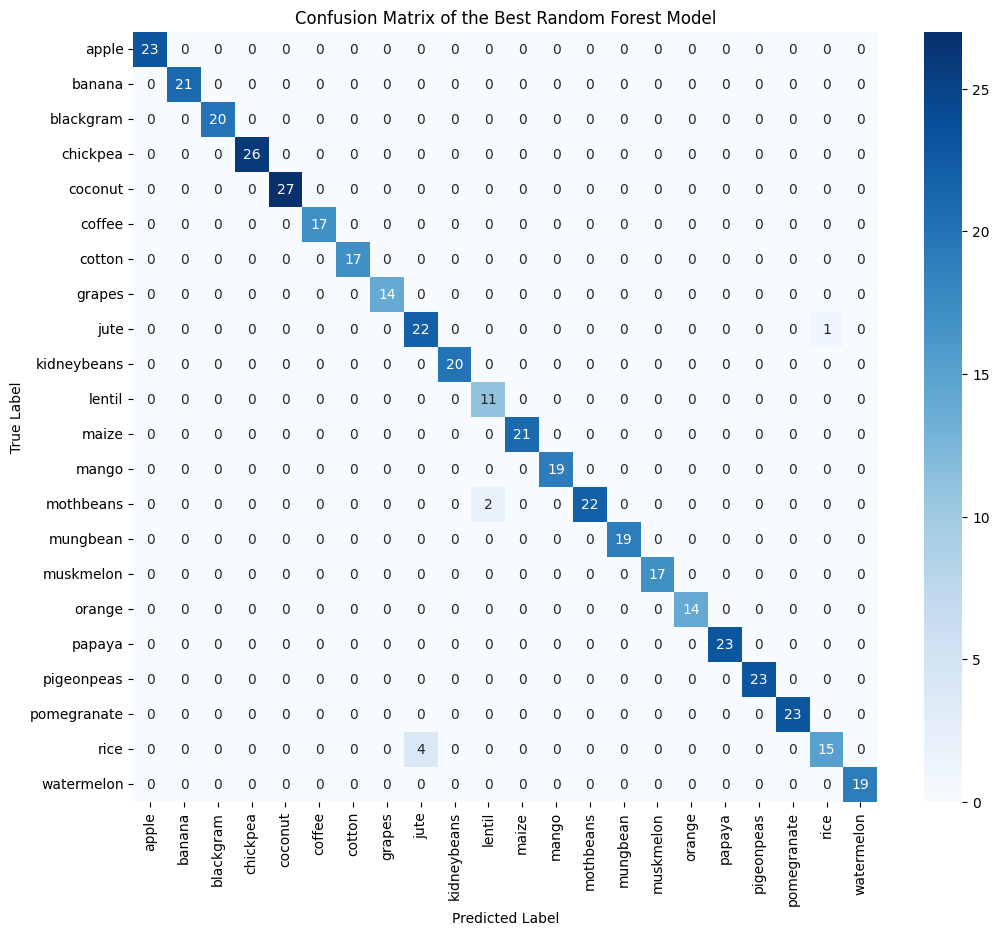

In [40]:
# Plotting the Confusion Matrix
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=best_rf_model.classes_, yticklabels=best_rf_model.classes_)
plt.title("Confusion Matrix of the Best Random Forest Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

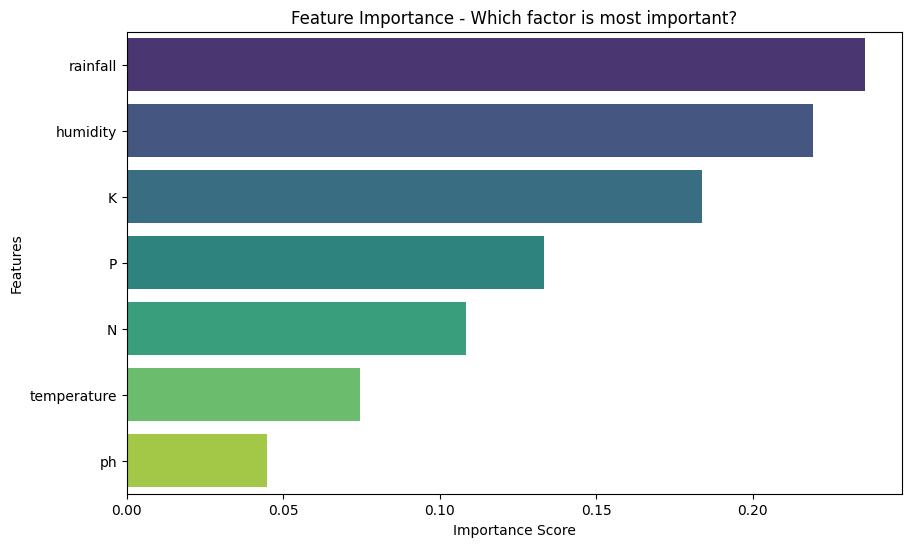

In [41]:
# Feature Importance Graph
# This shows which soil/climate factor affects the crop prediction the most
plt.figure(figsize=(10, 6))
feature_importances = pd.Series(best_rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
sns.barplot(x=feature_importances, y=feature_importances.index, palette='viridis')
plt.title("Feature Importance - Which factor is most important?")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [42]:
import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:

def predict_crop(N, P, K, temperature, humidity, ph, rainfall):
    input_data = np.array([[N, P, K, temperature, humidity, ph, rainfall]])
    scaled_input = scaler.transform(input_data)
    prediction = best_rf_model.predict(scaled_input)
    return f"🌟 The most suitable crop for this condition is: {prediction[0].upper()} 🌟"

In [44]:

def generate_dashboard():

    fig1 = plt.figure(figsize=(8, 5))
    sns.heatmap(df.drop('label', axis=1).corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title("Correlation Between Soil Features")
    plt.tight_layout()

    fig2 = plt.figure(figsize=(8, 5))
    feature_importances = pd.Series(best_rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
    sns.barplot(x=feature_importances, y=feature_importances.index, palette='viridis')
    plt.title("Which factor is most important?")
    plt.xlabel("Importance Score")
    plt.tight_layout()

    return fig1, fig2

In [46]:

with gr.Blocks(theme="soft") as dashboard:
    gr.Markdown("<h1 style='text-align: center;'>🌱 Smart Crop Recommendation Dashboard</h1>")
    gr.Markdown("Enter the soil and climate details on the left, and view the AI's recommendation along with the analytics dashboard on the right.")

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### 📊 Enter Soil & Climate Data")
            N = gr.Number(label="Nitrogen (N)", value=90)
            P = gr.Number(label="Phosphorus (P)", value=42)
            K = gr.Number(label="Potassium (K)", value=43)
            temperature = gr.Number(label="Temperature (°C)", value=20.8)
            humidity = gr.Number(label="Humidity (%)", value=82.0)
            ph = gr.Number(label="pH Value", value=6.5)
            rainfall = gr.Number(label="Rainfall (mm)", value=202.9)

            predict_btn = gr.Button("Predict Best Crop", variant="primary")

        with gr.Column(scale=2):
            gr.Markdown("### 🎯 Model Recommendation")
            output_text = gr.Textbox(label="Result", lines=2)

            gr.Markdown("### 📈 Analytics Dashboard")
            with gr.Row():
                heatmap_plot = gr.Plot(label="Feature Correlation")
                importance_plot = gr.Plot(label="Feature Importance")


            load_dashboard_btn = gr.Button("Load Analytics Dashboard")

    predict_btn.click(fn=predict_crop, inputs=[N, P, K, temperature, humidity, ph, rainfall], outputs=output_text)
    load_dashboard_btn.click(fn=generate_dashboard, inputs=[], outputs=[heatmap_plot, importance_plot])

dashboard.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://1c2cfce4d5b6b8f7ec.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://1c2cfce4d5b6b8f7ec.gradio.live
